# Breast cancer Bayesian logistic regression (31-D)

The target is the posterior of a Bayesian logistic regression on the Wisconsin Diagnostic
Breast Cancer (WDBC) data. It has $d=31$ dimensions (30 standardised features and an
intercept) and a $\mathcal N(0,10^2 I)$ prior on the weights, and it is fitted on the training
half of the 569 patients. The other half is held out for the test accuracy in section 6.

$$\pi(\theta\mid\mathcal D)\;\propto\;\Big[\textstyle\prod_{n\in\mathrm{train}}
\sigma(x_n^\top\theta)^{y_n}\big(1-\sigma(x_n^\top\theta)\big)^{1-y_n}\Big]\;
\mathcal N(\theta;\,0,\,10^2 I)$$

The posterior is unimodal, log-concave and close to Gaussian, but badly conditioned: the data
pin most coordinates tightly, while one direction stays almost as wide as the prior.

Each method fits a mixture of $K=3$ components for 200 iterations from a shared
initialisation. The settings are in `configs/breast_cancer.toml`.

In [1]:
%matplotlib inline
# Figures are embedded in the notebook as PNG (displayed) and vector PDF; none is written to disk.
%config InlineBackend.figure_formats = ["png", "pdf"]
import os
# Pin the kernel to ONE physical GPU BEFORE importing JAX (indices change between sessions --
# re-check `nvidia-smi` and pick an idle card). CPU also works: this notebook only loads saved
# results and re-evaluates the d=31 log-posterior on stored snapshots.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
jax.config.update("jax_enable_x64", True)

from gmmvi import benchmark, metrics, plotting

GROUP   = "breast_cancer"                # configs/breast_cancer.toml <-> results/breast_cancer.npz
CFG     = benchmark.load_config(GROUP)

## 1. The saved run

In [2]:
RESULTS = benchmark.require_results(GROUP)
SEEDS   = sorted({s for _, s in RESULTS})
METHODS = [m for m in ["ibw", "gmbbvi", "semtrux", "WFR"] if any(k[0] == m for k in RESULTS)]
GROUPED = benchmark.group_seeds(RESULTS, METHODS)

SPREAD  = "std"
SEED    = SEEDS[0]
RES     = {m: GROUPED[m][SEED] for m in METHODS}
K       = RES[METHODS[0]].K
m0      = RES[METHODS[0]].means_log[0]

## 2. The target

In [3]:
from gmmvi.targets import registry

spec = registry.build(CFG.get("target", GROUP))
bc   = spec.meta["problem"]
DIM  = spec.dim

## 3. The shared initialisation

Every method starts from the same mixture. The means are drawn from $\mathcal N(0,\,2^2 I)$,
near the prior centre, and the covariances are $10^{-5}I$. 

In [4]:
_init = benchmark.make_init(CFG, spec, SEED)
assert np.array_equal(_init.means, m0), "the config's init does not reproduce the stored means"
assert np.allclose(_init.covariances, _init.covariances[0, 0, 0] * np.eye(DIM))
for m in METHODS:
    assert np.allclose(RES[m].means_log[0], m0), f"{m} started from a different init?"
    assert np.allclose(RES[m].covs_log[0], _init.covariances, rtol=1e-6, atol=0), m
print("init means:       ||m_k|| in [%.1f, %.1f]"
      % (np.linalg.norm(m0, axis=1).min(), np.linalg.norm(m0, axis=1).max()))
print("init covariances: %.0e * I" % _init.covariances[0, 0, 0])

init means:       ||m_k|| in [10.5, 12.8]
init covariances: 1e-05 * I


## 5. Convergence


IBW     : -ELBO       7922.3 ->    208.7 (mean of 5 seeds)
GMBBVI  : -ELBO       7922.3 ->    519.7 (mean of 5 seeds)
SEMTRUX : -ELBO       7922.3 ->     51.3 (mean of 5 seeds)
WFR     : -ELBO       7922.3 ->     50.9 (mean of 5 seeds)


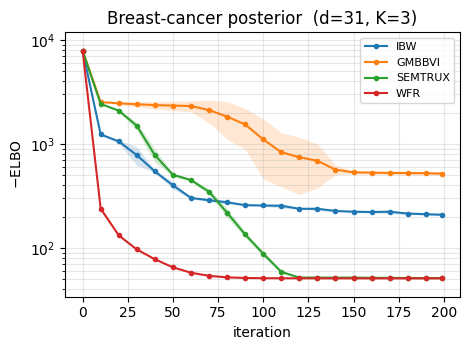

In [5]:
KL_ITERS, KLS = benchmark.kl_traces(GROUPED, spec=spec, config=CFG)

for m in METHODS:
    Y    = KLS[m]
    mean = np.nanmean(np.where(np.isfinite(Y), Y, np.nan), axis=0)
    print(f"{plotting.LABELS[m]:8s}: -ELBO {mean[0]:12.1f} -> {mean[-1]:8.1f} "
          f"(mean of {len(Y)} seeds)")

plotting.trace_panel({m: (KL_ITERS, KLS[m]) for m in METHODS},
                     ylabel=r"$-$ELBO",
                     title=f"Breast-cancer posterior  (d={DIM}, K={K})",
                     logy="auto", figsize=(4.8, 3.6), spread=SPREAD)
plt.tight_layout(); plt.show()

## 6. Test accuracy

At each checkpoint, 1000 weight vectors are sampled from the stored mixture, the predicted
class probabilities are averaged over them, and the result is scored on the held-out half.

This target writes the likelihood as $p(y=1\mid x,\theta)=\sigma(-x^\top\theta)$, with $y=1$
malignant. The averaged $\sigma(x^\top\theta)$ is therefore the benign probability, and a
patient is classified as malignant when it falls below 0.5.

A checkpoint where a method's mixture has blown up has no accuracy and shows as a gap in its
curve.

IBW     : test accuracy 0.665 -> 0.943 (mean of 5 seeds, last usable)
GMBBVI  : test accuracy 0.665 -> 0.793 (mean of 5 seeds, last usable)
SEMTRUX : test accuracy 0.665 -> 0.947 (mean of 5 seeds, last usable)
WFR     : test accuracy 0.665 -> 0.947 (mean of 5 seeds, last usable)


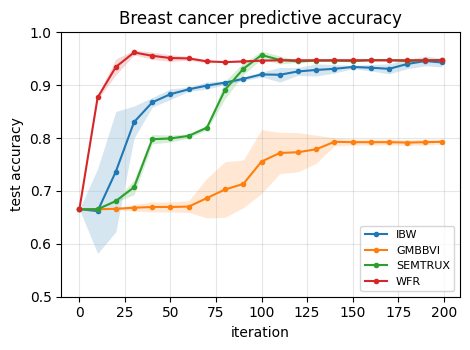

In [6]:
from gmmvi.targets.breast_cancer import sample_gmm, posterior_predictive_accuracy

X_test = np.asarray(bc.X_test); y_test = np.asarray(bc.y_test).reshape(-1)
S_PP     = 1000     # Monte-Carlo theta samples per checkpoint
_PP_SEED = 0        # common random numbers across checkpoints AND seeds -> smooth curves

def _accuracy_trace(r):
    """Posterior-predictive accuracy at every checkpoint of ONE run (nan where unusable)."""
    accs = []
    for i in range(len(np.asarray(r.iters))):
        mns, cvs, ws = r.means_log[i], r.covs_log[i], r.weights_log[i]
        if not (np.isfinite(mns).all() and np.isfinite(cvs).all() and np.isfinite(ws).all()):
            accs.append(np.nan)
            continue
        try:
            theta = sample_gmm(mns, cvs, ws, num_samples=S_PP, seed=_PP_SEED)
        except np.linalg.LinAlgError:
            accs.append(np.nan)
            continue
        accs.append(posterior_predictive_accuracy(X_test, y_test, theta)[1])
    return np.asarray(accs, float)

ACC = {m: np.stack([_accuracy_trace(r) for _, r in sorted(GROUPED[m].items())])
       for m in METHODS}

for m in METHODS:
    Y  = ACC[m]
    ok = np.isfinite(Y)
    mean = np.nanmean(np.where(ok, Y, np.nan), axis=0)
    last = mean[np.isfinite(mean)][-1] if np.isfinite(mean).any() else float("nan")
    print(f"{plotting.LABELS[m]:8s}: test accuracy {mean[0]:.3f} -> {last:.3f} "
          f"(mean of {len(Y)} seeds, last usable)")

ax = plotting.trace_panel({m: (RES[m].iters, ACC[m]) for m in METHODS},
                          ylabel="test accuracy", logy=False, figsize=(4.8, 3.6),
                          spread=SPREAD,
                          title="Breast cancer predictive accuracy")
ax.set_ylim(0.5, 1.0)
plt.tight_layout(); plt.show()